# Auralis: next-period English failure risk

This notebook estimates next-period subject failure risk from completed previous-period records. It uses historical English quarter transitions, with Phil-IRI as an English reading baseline.


## 1. Exploratory Data Analysis

Load and describe the source CSV. These plots describe the full cohort, including eventual TEST learners; they do not provide unseen-test evidence.


In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("../Data Frame/model_recent-dataFrame.csv")
if not data_path.is_file():
    data_path = Path("Data Frame/model_recent-dataFrame.csv")
data_path = data_path.resolve()
df = pd.read_csv(data_path)

display(df.head())
print("Rows and columns:", df.shape)
df.info()
display(df.describe())
print('Learners:', df.learner_id.nunique())


,transition_id,learner_id,section_id,subject_id,school_year,period_type,previous_period,prediction_period,grading_policy_id,ww_pct,...,previous_grade_change,previous_grade_change_missing,phil_iri_literal_pct,phil_iri_inferential_pct,phil_iri_critical_pct,phil_iri_unavailable,absence_rate,attendance_missing,final_subject_grade,is_at_risk
0,CAY-001-ENGLISH-2025-2026-Q1-Q2,CAY-001,G8-CAYETANO,ENGLISH,2025-2026,QUARTER,Q1,Q2,WW30_PT50_QA20,54.65,...,NaN,True,14.285714,58.333333,14.285714,False,0.000000,False,79.0,0
1,CAY-001-ENGLISH-2025-2026-Q2-Q3,CAY-001,G8-CAYETANO,ENGLISH,2025-2026,QUARTER,Q2,Q3,WW30_PT50_QA20,48.57,...,-5.0,False,14.285714,58.333333,14.285714,False,0.000000,False,83.0,0
2,CAY-001-ENGLISH-2025-2026-Q3-Q4,CAY-001,G8-CAYETANO,ENGLISH,2025-2026,QUARTER,Q3,Q4,WW30_PT50_QA20,64.40,...,4.0,False,14.285714,58.333333,14.285714,False,0.000000,False,73.0,1
3,CAY-002-ENGLISH-2025-2026-Q1-Q2,CAY-002,G8-CAYETANO,ENGLISH,2025-2026,QUARTER,Q1,Q2,WW30_PT50_QA20,41.41,...,NaN,True,7.142857,50.000000,28.571429,False,0.083333,False,80.0,0
4,CAY-002-ENGLISH-2025-2026-Q2-Q3,CAY-002,G8-CAYETANO,ENGLISH,2025-2026,QUARTER,Q2,Q3,WW30_PT50_QA20,42.86,...,8.0,False,7.142857,50.000000,28.571429,False,0.262500,False,75.0,0


Rows and columns: (249, 27)
<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   transition_id                  249 non-null    str    
 1   learner_id                     249 non-null    str    
 2   section_id                     249 non-null    str    
 3   subject_id                     249 non-null    str    
 4   school_year                    249 non-null    str    
 5   period_type                    249 non-null    str    
 6   previous_period                249 non-null    str    
 7   prediction_period              249 non-null    str    
 8   grading_policy_id              249 non-null    str    
 9   ww_pct                         249 non-null    float64
 10  pt_pct                         249 non-null    float64
 11  qa_pct                         249 non-null    float64
 12  ww_task_count                  24

,ww_pct,pt_pct,qa_pct,ww_task_count,pt_task_count,ww_score_coverage_rate,pt_score_coverage_rate,previous_final_grade,previous_grade_change,phil_iri_literal_pct,phil_iri_inferential_pct,phil_iri_critical_pct,absence_rate,final_subject_grade,is_at_risk
count,249.000000,249.000000,249.000000,249.000000,249.000000,249.000000,249.000000,249.000000,165.000000,241.000000,241.000000,241.000000,208.000000,249.000000,249.000000
mean,59.062450,85.738835,57.903614,8.827309,2.839357,0.950258,0.966667,83.132530,0.484848,27.978660,41.108477,28.447935,0.058348,82.253012,0.204819
std,20.614892,13.413525,18.010491,1.217438,1.570358,0.119597,0.115848,6.941758,4.809297,20.795920,20.656851,15.914580,0.099846,8.193492,0.404382
min,0.000000,0.000000,16.000000,7.000000,1.000000,0.250000,0.250000,61.000000,-14.000000,0.000000,0.000000,7.142857,0.000000,61.000000,0.000000
25%,44.440000,82.860000,44.000000,8.000000,1.000000,1.000000,1.000000,78.000000,-1.000000,14.285714,28.571429,16.666667,0.000000,77.000000,0.000000
50%,62.540000,88.670000,56.000000,8.000000,4.000000,1.000000,1.000000,83.000000,1.000000,28.571429,41.666667,25.000000,0.010417,83.000000,0.000000
75%,74.400000,95.000000,74.000000,10.000000,4.000000,1.000000,1.000000,89.000000,2.000000,42.857143,50.000000,35.714286,0.065217,88.000000,0.000000
max,97.600000,100.000000,100.000000,10.000000,5.000000,1.000000,1.000000,95.000000,13.000000,100.000000,100.000000,85.714286,0.608696,96.000000,1.000000


Learners: 84


### Class balance, missing values and correlations

These plots describe the full historical cohort, including TEST learners.
They show associations and missing records; they do not establish causes.


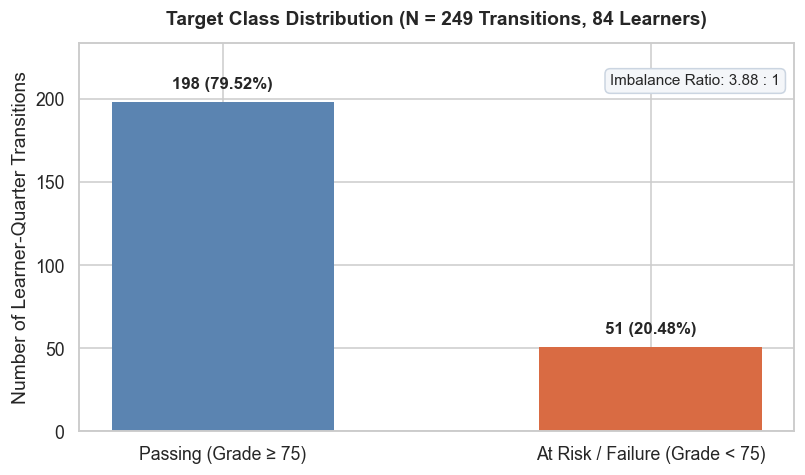

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
eda = df.copy()
eda_figures = {}

# Target Class Imbalance (Passing vs. At Risk)
class_counts = eda["is_at_risk"].value_counts().reindex([0, 1], fill_value=0)
total_rows = int(class_counts.sum())
imbalance_ratio = class_counts[0] / max(class_counts[1], 1)
class_imbalance_figure, ax = plt.subplots(figsize=(7.5, 4.5))
labels = ["Passing (Grade ≥ 75)", "At Risk / Failure (Grade < 75)"]
colors = ["#5B84B1", "#D96B43"]
bars = ax.bar(labels, [class_counts[0], class_counts[1]], color=colors, width=0.52, edgecolor="none")
for bar, count in zip(bars, [class_counts[0], class_counts[1]]):
    pct = (count / total_rows) * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + total_rows * 0.025,
        f"{count} ({pct:.2f}%)",
        ha="center", va="bottom", fontweight="bold", fontsize=11
    )
ax.set_title(
    f"Target Class Distribution (N = {total_rows} Transitions, {eda['learner_id'].nunique()} Learners)",
    fontweight="bold", pad=12
)
ax.set_ylabel("Number of Learner-Quarter Transitions")
ax.set_ylim(0, max(class_counts) * 1.18)
ax.text(
    0.98, 0.92, f"Imbalance Ratio: {imbalance_ratio:.2f} : 1",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=10, bbox=dict(boxstyle="round,pad=0.35", facecolor="#F4F6F9", edgecolor="#CBD5E1")
)
plt.tight_layout()
eda_figures["class_imbalance.png"] = class_imbalance_figure
plt.show()

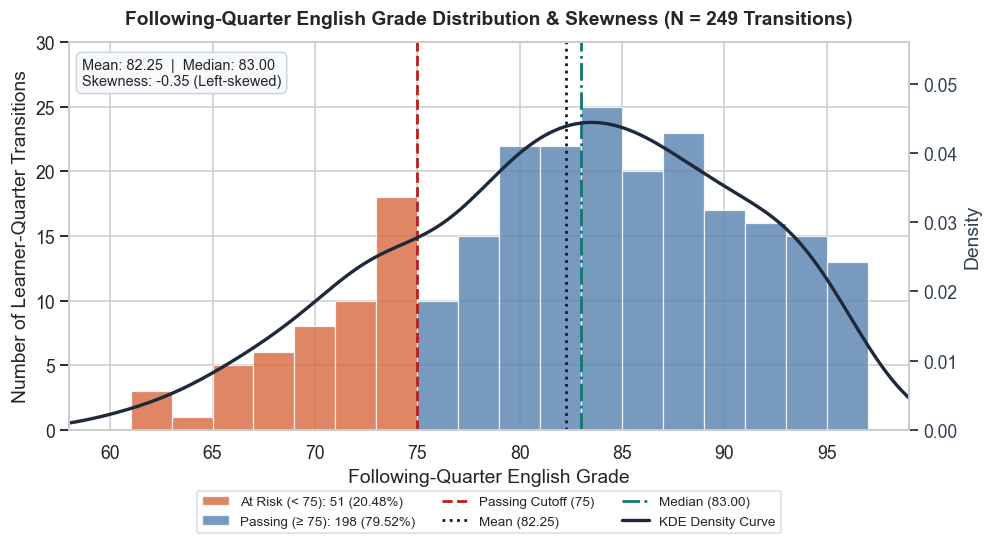

In [3]:
# Target Grade Distribution & Skewness (Following-Quarter English Grade)
grades = eda["final_subject_grade"].dropna()
grade_mean = float(grades.mean())
grade_median = float(grades.median())
grade_skew = float(grades.skew())
bins = np.arange(59, 99, 2)

target_skew_figure, ax = plt.subplots(figsize=(9.2, 5.2))
failing_grades = grades[grades < 75]
passing_grades = grades[grades >= 75]
ax.hist(failing_grades, bins=bins, color="#D96B43", alpha=0.82, edgecolor="white", linewidth=0.8, label=f"At Risk (< 75): {len(failing_grades)} ({len(failing_grades)/len(grades)*100:.2f}%)")
ax.hist(passing_grades, bins=bins, color="#5B84B1", alpha=0.82, edgecolor="white", linewidth=0.8, label=f"Passing (≥ 75): {len(passing_grades)} ({len(passing_grades)/len(grades)*100:.2f}%)")

ax2 = ax.twinx()
sns.kdeplot(grades, ax=ax2, color="#1E293B", linewidth=2.2, bw_adjust=1.0, label="KDE Density Curve")
ax2.set_ylabel("Density", color="#334155")
ax2.tick_params(axis="y", colors="#334155")
ax2.grid(False)

ax.axvline(75, color="#B91C1C", linestyle="--", linewidth=1.8, label="Passing Cutoff (75)")
ax.axvline(grade_mean, color="#0F172A", linestyle=":", linewidth=1.8, label=f"Mean ({grade_mean:.2f})")
ax.axvline(grade_median, color="#0F766E", linestyle="-.", linewidth=1.8, label=f"Median ({grade_median:.2f})")

ax.set_title("Following-Quarter English Grade Distribution & Skewness (N = 249 Transitions)", fontweight="bold", pad=12)
ax.set_xlabel("Following-Quarter English Grade")
ax.set_ylabel("Number of Learner-Quarter Transitions")
ax.set_xlim(58, 99)
ax.set_ylim(0, 30)
ax2.set_ylim(0, 0.056)

stats_text = (
    f"Mean: {grade_mean:.2f}  |  Median: {grade_median:.2f}\n"
    f"Skewness: {grade_skew:+.2f} (Left-skewed)"
)
ax.text(
    0.015, 0.96, stats_text,
    transform=ax.transAxes, ha="left", va="top", fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.38", facecolor="#F8FAFC", edgecolor="#CBD5E1")
)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(
    h1 + h2, l1 + l2,
    loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3,
    fontsize=8.8, frameon=True, facecolor="white", edgecolor="#CBD5E1"
)
plt.tight_layout()
eda_figures["target_grade_skewness.png"] = target_skew_figure
plt.show()

rows  failures failure_rate
section_id  prediction_period                             
G8-CAYETANO Q2                   41        15       36.59%
            Q3                   42         6       14.29%
            Q4                   42        27       64.29%
G8-DEFENSOR Q2                   42         1        2.38%
            Q3                   41         1        2.44%
            Q4                   41         1        2.44%

,missing_rows,missing_fraction
ww_pct,0.0,0.000000
pt_pct,0.0,0.000000
qa_pct,0.0,0.000000
previous_final_grade,0.0,0.000000
ww_task_count,0.0,0.000000
pt_task_count,0.0,0.000000
ww_score_coverage_rate,0.0,0.000000
pt_score_coverage_rate,0.0,0.000000
phil_iri_literal_pct,8.0,0.032129
phil_iri_inferential_pct,8.0,0.032129


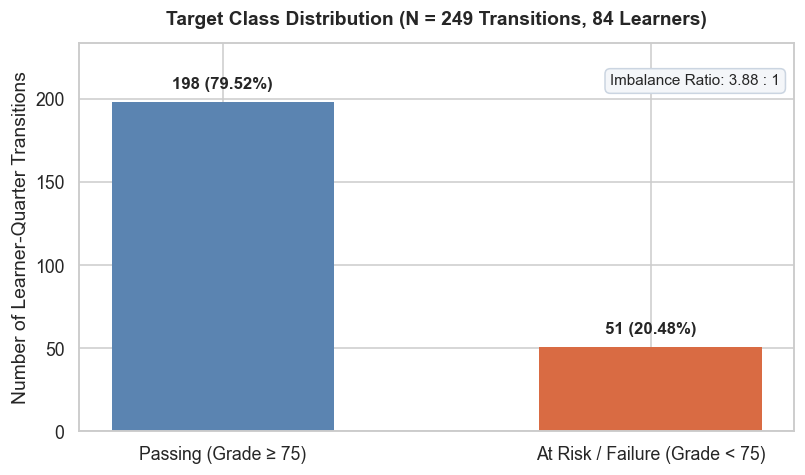

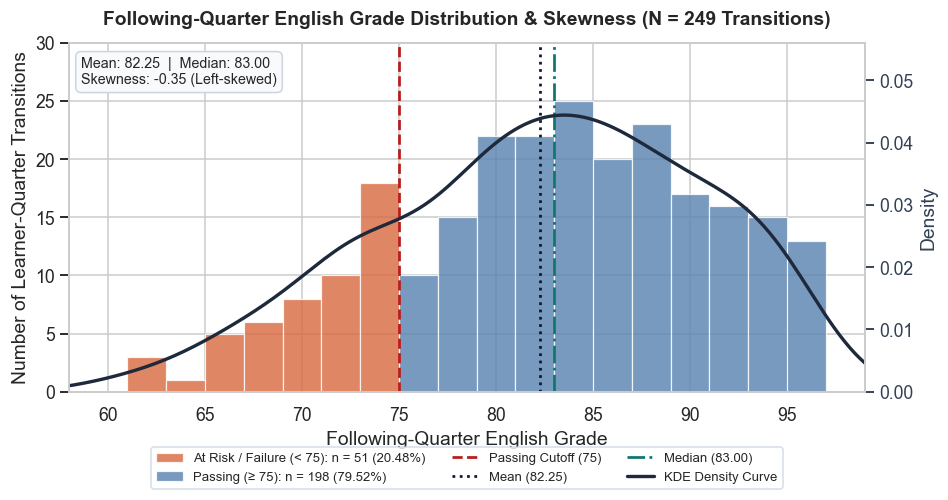

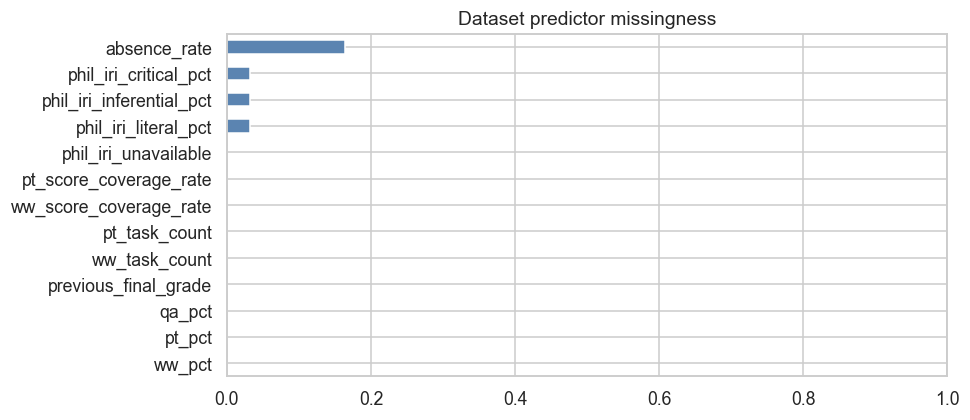

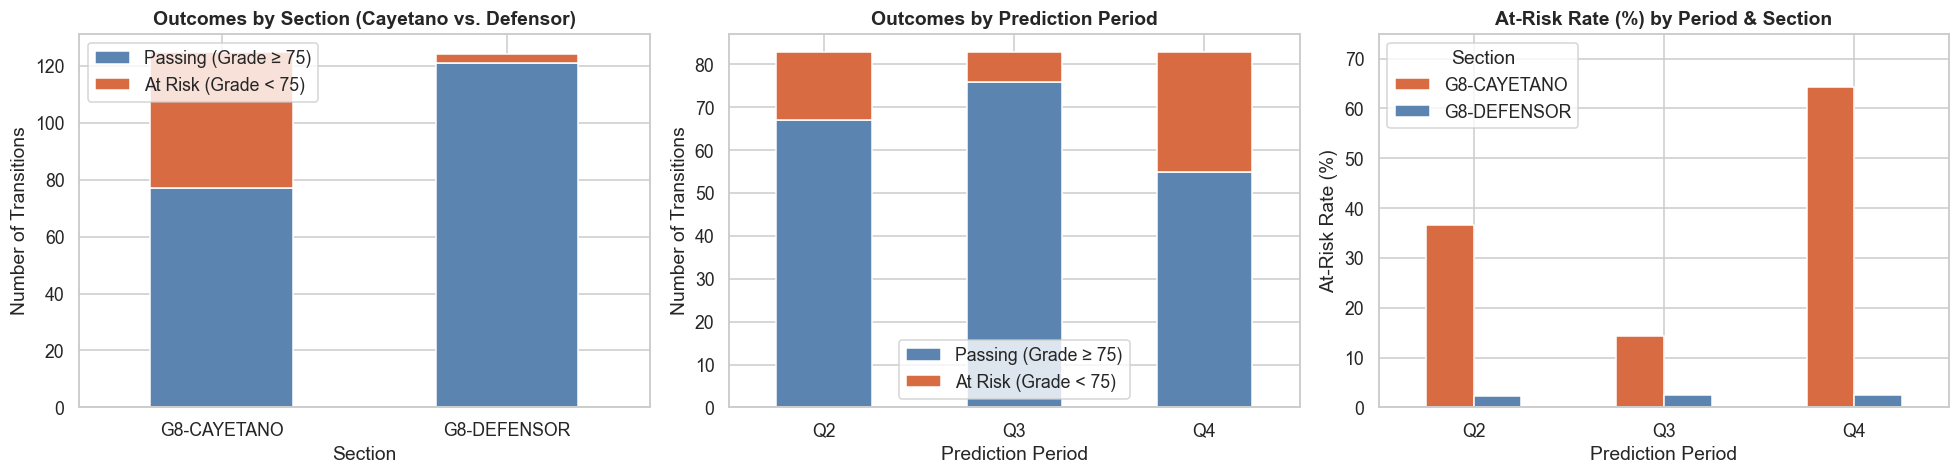

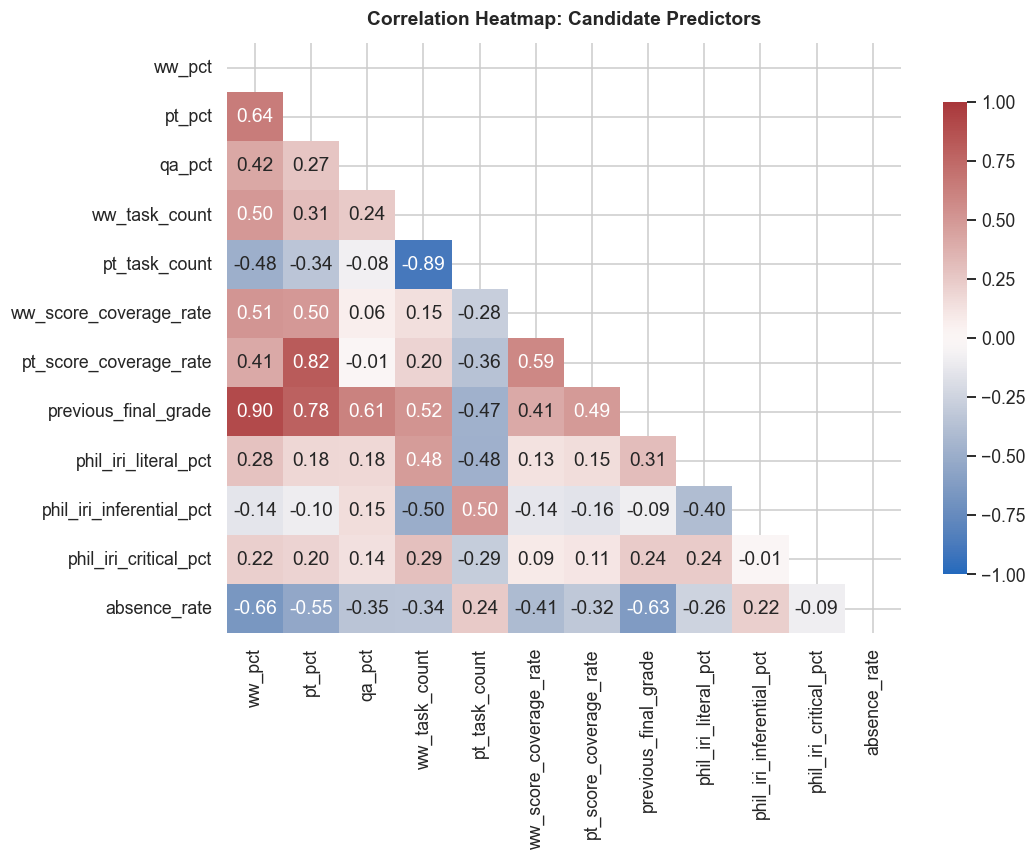

In [4]:
eda_columns = [
    "ww_pct", "pt_pct", "qa_pct", "previous_final_grade",
    "ww_task_count", "pt_task_count", "ww_score_coverage_rate", "pt_score_coverage_rate",
    "phil_iri_literal_pct", "phil_iri_inferential_pct", "phil_iri_critical_pct",
    "phil_iri_unavailable", "absence_rate",
]
display(eda.groupby(["section_id", "prediction_period"]).agg(
    rows=("is_at_risk", "size"), failures=("is_at_risk", "sum"),  failure_rate=("is_at_risk", lambda x: f"{x.mean() * 100:.2f}%")))
missingness = eda[eda_columns].isna().agg(["sum", "mean"]).T
missingness.columns = ["missing_rows", "missing_fraction"]
display(missingness)
# Visualization: Overall Target Class Imbalance
class_counts = eda["is_at_risk"].value_counts().reindex([0, 1], fill_value=0)
total_rows = int(class_counts.sum())
imbalance_ratio = class_counts[0] / max(class_counts[1], 1)
class_imbalance_figure, ax = plt.subplots(figsize=(7.5, 4.5))
labels = ["Passing (Grade ≥ 75)", "At Risk / Failure (Grade < 75)"]
colors = ["#5B84B1", "#D96B43"]
bars = ax.bar(labels, [class_counts[0], class_counts[1]], color=colors, width=0.52, edgecolor="none")
for bar, count in zip(bars, [class_counts[0], class_counts[1]]):
    pct = (count / total_rows) * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + total_rows * 0.025,
        f"{count} ({pct:.2f}%)",
        ha="center", va="bottom", fontweight="bold", fontsize=11
    )
ax.set_title(
    f"Target Class Distribution (N = {total_rows} Transitions, {eda['learner_id'].nunique()} Learners)",
    fontweight="bold", pad=12
)
ax.set_ylabel("Number of Learner-Quarter Transitions")
ax.set_ylim(0, max(class_counts) * 1.18)
ax.text(
    0.98, 0.92, f"Imbalance Ratio: {imbalance_ratio:.2f} : 1",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=10, bbox=dict(boxstyle="round,pad=0.35", facecolor="#F4F6F9", edgecolor="#CBD5E1")
)
plt.tight_layout()
eda_figures["class_imbalance.png"] = class_imbalance_figure
plt.show()

# Visualization: Target Grade Distribution & Skewness (Following-Quarter English Grade)
grades = eda["final_subject_grade"].dropna()
grade_mean = float(grades.mean())
grade_median = float(grades.median())
grade_skew = float(grades.skew())
bins = np.arange(59, 99, 2)  # Bin boundary lands cleanly on 75

target_skew_figure, ax = plt.subplots(figsize=(8.8, 4.8))
failing_grades = grades[grades < 75]
passing_grades = grades[grades >= 75]
ax.hist(failing_grades, bins=bins, color="#D96B43", alpha=0.82, edgecolor="white", linewidth=0.8, label=f"At Risk / Failure (< 75): n = {len(failing_grades)} ({len(failing_grades)/len(grades)*100:.2f}%)")
ax.hist(passing_grades, bins=bins, color="#5B84B1", alpha=0.82, edgecolor="white", linewidth=0.8, label=f"Passing (≥ 75): n = {len(passing_grades)} ({len(passing_grades)/len(grades)*100:.2f}%)")

ax2 = ax.twinx()
sns.kdeplot(grades, ax=ax2, color="#1E293B", linewidth=2.2, bw_adjust=1.0, label="KDE Density Curve")
ax2.set_ylabel("Density", color="#334155")
ax2.tick_params(axis="y", colors="#334155")
ax2.grid(False)

ax.axvline(75, color="#B91C1C", linestyle="--", linewidth=1.8, label="Passing Cutoff (75)")
ax.axvline(grade_mean, color="#0F172A", linestyle=":", linewidth=1.8, label=f"Mean ({grade_mean:.2f})")
ax.axvline(grade_median, color="#0F766E", linestyle="-.", linewidth=1.8, label=f"Median ({grade_median:.2f})")

ax.set_title("Following-Quarter English Grade Distribution & Skewness (N = 249 Transitions)", fontweight="bold", pad=12)
ax.set_xlabel("Following-Quarter English Grade")
ax.set_ylabel("Number of Learner-Quarter Transitions")
ax.set_xlim(58, 99)
ax.set_ylim(0, 30)
ax2.set_ylim(0, 0.056)

stats_text = (
    f"Mean: {grade_mean:.2f}  |  Median: {grade_median:.2f}\n"
    f"Skewness: {grade_skew:+.2f} (Left-skewed)"
)
ax.text(
    0.015, 0.96, stats_text,
    transform=ax.transAxes, ha="left", va="top", fontsize=9.3,
    bbox=dict(boxstyle="round,pad=0.38", facecolor="#F8FAFC", edgecolor="#CBD5E1")
)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(
    h1 + h2, l1 + l2,
    loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3,
    fontsize=8.6, frameon=True, facecolor="white", edgecolor="#CBD5E1"
)
plt.tight_layout()
eda_figures["target_grade_skewness.png"] = target_skew_figure
plt.show()


fig, ax = plt.subplots(figsize=(9, 4))
missingness["missing_fraction"].sort_values().plot.barh(ax=ax, color="#5B84B1")
ax.set_title("Dataset predictor missingness"); ax.set_xlim(0, 1)
plt.tight_layout(); eda_figures["missingness.png"] = fig; plt.show(); plt.close(fig)

# Visualization: Outcome distribution by section, period, and section-by-period
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Plot 1: By Section
sec_df = eda.groupby(["section_id", "is_at_risk"]).size().unstack(fill_value=0)
sec_df.plot(kind="bar", stacked=True, color=["#5B84B1", "#D96B43"], ax=axes[0])
axes[0].set_title("Outcomes by Section (Cayetano vs. Defensor)", fontweight="bold")
axes[0].set_xlabel("Section")
axes[0].set_ylabel("Number of Transitions")
axes[0].legend(["Passing (Grade ≥ 75)", "At Risk (Grade < 75)"], frameon=True)
axes[0].tick_params(axis="x", rotation=0)

# Plot 2: By Prediction Period
per_df = eda.groupby(["prediction_period", "is_at_risk"]).size().unstack(fill_value=0)
per_df.plot(kind="bar", stacked=True, color=["#5B84B1", "#D96B43"], ax=axes[1])
axes[1].set_title("Outcomes by Prediction Period", fontweight="bold")
axes[1].set_xlabel("Prediction Period")
axes[1].set_ylabel("Number of Transitions")
axes[1].legend(["Passing (Grade ≥ 75)", "At Risk (Grade < 75)"], frameon=True)
axes[1].tick_params(axis="x", rotation=0)

# Plot 3: Cross-tabulated At-Risk Rate by Period across Sections
sec_per_rate = eda.groupby(["prediction_period", "section_id"])["is_at_risk"].mean().unstack() * 100
sec_per_rate.plot(kind="bar", color=["#D96B43", "#5B84B1"], ax=axes[2])
axes[2].set_title("At-Risk Rate (%) by Period & Section", fontweight="bold")
axes[2].set_xlabel("Prediction Period")
axes[2].set_ylabel("At-Risk Rate (%)")
axes[2].set_ylim(0, 75)
axes[2].legend(title="Section", frameon=True)
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
eda_figures["01_outcome_distributions.png"] = fig
plt.show()
plt.close(fig)
continuous_candidates = [
    "ww_pct", "pt_pct", "qa_pct",
    "ww_task_count", "pt_task_count",
    "ww_score_coverage_rate", "pt_score_coverage_rate",
    "previous_final_grade",
    "phil_iri_literal_pct", "phil_iri_inferential_pct", "phil_iri_critical_pct",
    "absence_rate"
]

corr = eda[continuous_candidates].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="vlag", vmin=-1, vmax=1, annot=True, fmt=".2f", cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap: Candidate Predictors", fontweight="bold", pad=12)
plt.tight_layout()
corr_fig = plt.gcf()
eda_figures["04_correlation_heatmap.png"] = corr_fig
plt.show()
plt.close(corr_fig)

### Academic, attendance and reading patterns

These plots retain all three Phil-IRI sub-scores and the existing academic and
coverage views. Percentages use 0–100; absence and coverage rates use 0–1.
Task counts and coverage are descriptive fields only; the nine-input model excludes them.
Missing attendance is not perfect attendance. Associations are not causal explanations.

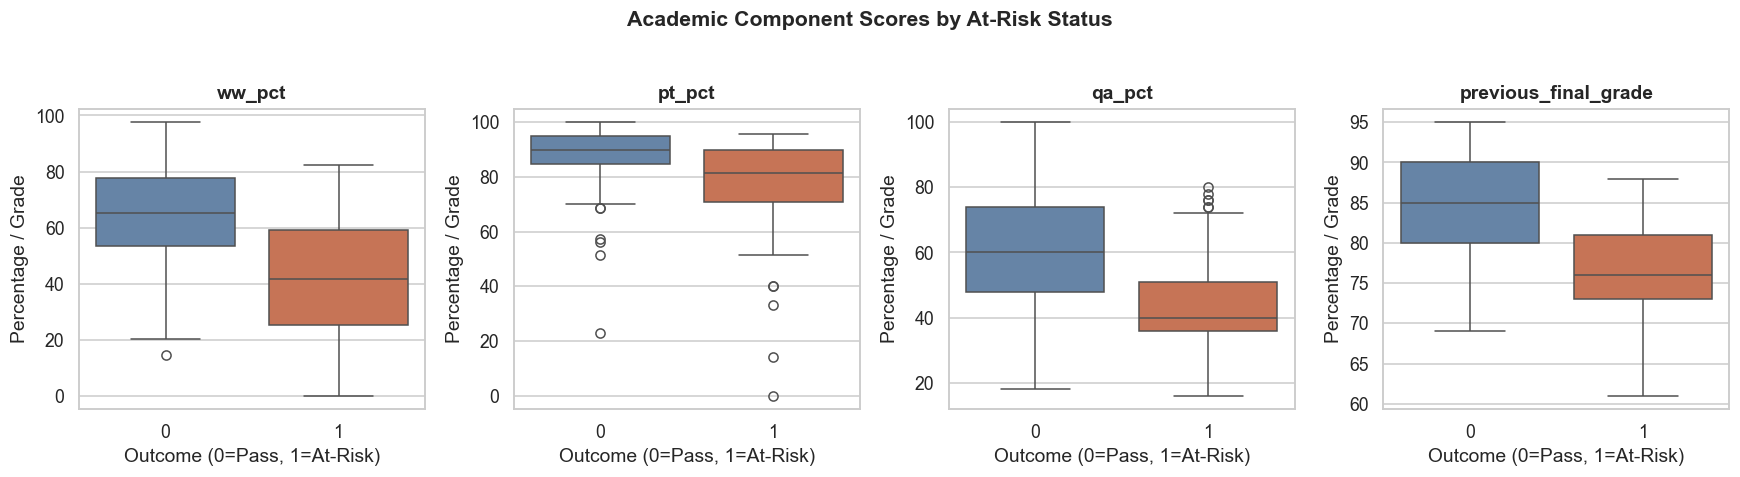

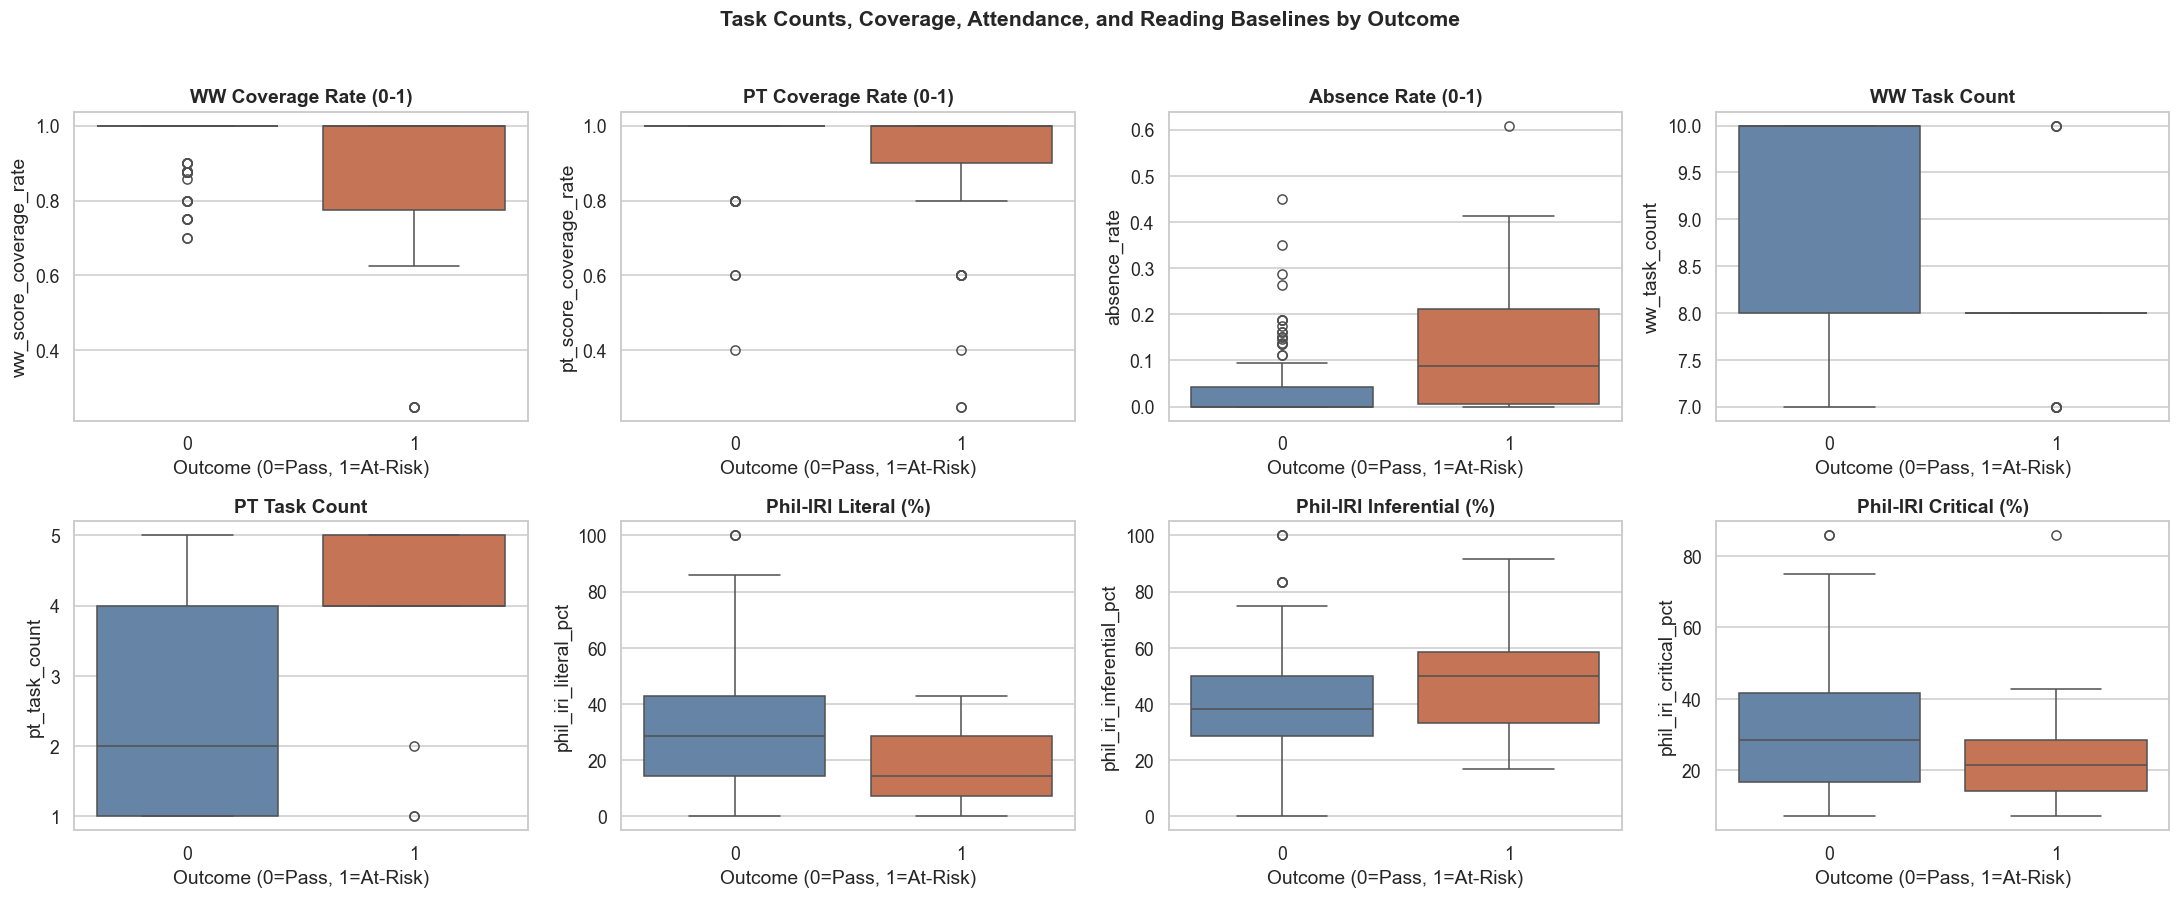

In [5]:
# Academic component comparisons
components = ["ww_pct", "pt_pct", "qa_pct", "previous_final_grade"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))

for ax, col in zip(axes, components):
    sns.boxplot(
        data=eda, x="is_at_risk", y=col, ax=ax,
        palette=["#5B84B1", "#D96B43"], hue="is_at_risk", legend=False
    )
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel("Outcome (0=Pass, 1=At-Risk)")
    ax.set_ylabel("Percentage / Grade")

plt.suptitle("Academic Component Scores by At-Risk Status", y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
eda_figures["02_academic_components_by_outcome.png"] = fig
plt.show()
plt.close("all")

# Task counts, Coverage Rates, Phil-IRI (all 3 levels), and Absence Rate comparisons
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

pattern_features = [
    ("ww_score_coverage_rate", "WW Coverage Rate (0-1)"),
    ("pt_score_coverage_rate", "PT Coverage Rate (0-1)"),
    ("absence_rate", "Absence Rate (0-1)"),
    ("ww_task_count", "WW Task Count"),
    ("pt_task_count", "PT Task Count"),
    ("phil_iri_literal_pct", "Phil-IRI Literal (%)"),
    ("phil_iri_inferential_pct", "Phil-IRI Inferential (%)"),
    ("phil_iri_critical_pct", "Phil-IRI Critical (%)"),
]

for ax, (col, title) in zip(axes.flat, pattern_features):
    sns.boxplot(
        data=eda, x="is_at_risk", y=col, ax=ax,
        palette=["#5B84B1", "#D96B43"], hue="is_at_risk", legend=False
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Outcome (0=Pass, 1=At-Risk)")

plt.suptitle("Task Counts, Coverage, Attendance, and Reading Baselines by Outcome", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
eda_figures["03_behavioral_reading_metrics.png"] = fig
plt.show()
plt.close("all")

## 2. TRAIN/TEST SPLIT
Keep the existing DEV/TEST allocation and five DEV folds. Every period from one learner stays
in the same partition and fold. The short checks below catch wrong labels, duplicate records,
invalid predictor values and learner overlap. Descriptive statistics alone do not catch these errors.


In [6]:
RANDOM_SEED = 42
TARGET, GROUP = "is_at_risk", "learner_id"
CV_FOLDS, HOLDOUT_FOLD = 5, 4

# Prepare Features
FEATURES = [
    "ww_pct", "pt_pct", "qa_pct", "previous_final_grade",
    "phil_iri_literal_pct", "phil_iri_inferential_pct", "phil_iri_critical_pct",
    "phil_iri_unavailable", "absence_rate",
]
PERCENT_FEATURES = [c for c in FEATURES if c.endswith("_pct")] + ["previous_final_grade"]
pipeline_dir = data_path.parent.parent / "Model Pipeline"
split_path = pipeline_dir / "outputs" / "learner_partitions.csv"

required = FEATURES + ["transition_id", GROUP, "section_id", "subject_id",
                      "previous_period", "prediction_period", "final_subject_grade", TARGET]
assert set(required).issubset(df.columns), "Required dataset columns are missing."
assert df["transition_id"].is_unique, "Duplicate transitions."
assert not df.duplicated([GROUP, "subject_id", "school_year", "previous_period", "prediction_period"]).any()
assert df[GROUP].notna().all()
assert df["subject_id"].astype(str).str.upper().eq("ENGLISH").all(), "This experiment is English only."
df[FEATURES] = df[FEATURES].apply(pd.to_numeric, errors="raise")
assert not np.isinf(df[FEATURES].to_numpy(dtype=float)).any()
assert df[PERCENT_FEATURES].apply(lambda s: s.dropna().between(0, 100).all()).all()
assert df["absence_rate"].dropna().between(0, 1).all()
assert df["phil_iri_unavailable"].isin([0, 1]).all()
assert df["final_subject_grade"].between(0, 100).all()
assert df[TARGET].isin([0, 1]).all()
assert df[TARGET].eq((df["final_subject_grade"] < 75).astype(int)).all(), "Label/grade mismatch."


In [7]:
from sklearn.model_selection import StratifiedGroupKFold

if split_path.is_file():
    partitions = pd.read_csv(split_path)
    assert set(partitions.transition_id) == set(df.transition_id), "Saved split differs from this dataset."
    df = df.merge(partitions[["transition_id", "partition", "cv_fold"]],
                  on="transition_id", validate="one_to_one")
else:
    # Only a new dataset without a saved split uses this branch.
    outer = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    dev_idx, test_idx = list(outer.split(df, df[TARGET], df[GROUP]))[HOLDOUT_FOLD]
    df["partition"], df["cv_fold"] = "DEV", -1
    df.loc[test_idx, "partition"] = "TEST"
    development = df.iloc[dev_idx]
    inner = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    for fold, (_, valid_idx) in enumerate(inner.split(development, development[TARGET], development[GROUP])):
        df.loc[development.iloc[valid_idx].index, "cv_fold"] = fold

assert df["partition"].isin(["DEV", "TEST"]).all()
assert df.groupby(GROUP)["partition"].nunique().eq(1).all(), "Learner crosses DEV/TEST."
dev_df = df[df.partition == "DEV"].copy()
test_df = df[df.partition == "TEST"].copy()
assert not dev_df.empty and not test_df.empty
assert set(dev_df.cv_fold) == set(range(CV_FOLDS)) and test_df.cv_fold.eq(-1).all()
assert dev_df.groupby(GROUP)["cv_fold"].nunique().eq(1).all(), "Learner crosses DEV folds."
for fold in range(CV_FOLDS):
    assert dev_df[dev_df.cv_fold != fold][TARGET].nunique() == 2
    assert dev_df[dev_df.cv_fold == fold][TARGET].nunique() == 2

display(df.groupby("partition").agg(
    learners=(GROUP, "nunique"), transitions=(TARGET, "size"), failures=(TARGET, "sum")))
display(dev_df.groupby("cv_fold").agg(
    learners=(GROUP, "nunique"), transitions=(TARGET, "size"), failures=(TARGET, "sum")))


,learners,transitions,failures
partition,,,
DEV,67,199,41
TEST,17,50,10


,learners,transitions,failures
cv_fold,,,
0,13,39,8
1,14,42,8
2,13,39,8
3,13,39,9
4,14,40,8


## 3. Preprocessing / Train

Each training fold fits a fresh Pipeline: median imputation, constant-feature removal,
scaling for Logistic Regression/SVM/Naive Bayes, then the classifier.
Validation records never fit those transformations.

Compare one reference configuration for each of the five algorithms. After the
algorithm/threshold comparison selects Random Forest, tune Random Forest only. Logistic Regression,
Decision Tree, Random Forest and SVM use balanced class weights. Gaussian Naive Bayes uses
balanced training sample weights. There is no oversampling or balancing-ratio search.
Balancing, the nine inputs and the saved learner folds stay fixed during tuning.
All hyperparameter and threshold choices are made on DEV, never TEST.


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

ALGORITHMS = ["logistic", "decision_tree", "random_forest", "svm", "gaussian_nb"]
MODEL_LABELS = {
    "logistic": "Logistic Regression", "decision_tree": "Decision Tree",
    "random_forest": "Random Forest", "svm": "SVM", "gaussian_nb": "Naive Bayes",
}

# CLeaning station
def build_pipeline(algorithm, balanced=True):
    weight = "balanced" if balanced else None
    models = {
        "logistic": LogisticRegression(C=1, solver="liblinear", max_iter=2000,
                                          class_weight=weight, random_state=RANDOM_SEED),
        "decision_tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5,
                                                class_weight=weight, random_state=RANDOM_SEED),
        "random_forest": RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=5,
                                                class_weight=weight, random_state=RANDOM_SEED, n_jobs=-1),
        "svm": SVC(C=1, kernel="rbf", gamma="scale", probability=True,
                   class_weight=weight, random_state=RANDOM_SEED),
        "gaussian_nb": GaussianNB(var_smoothing=1e-9),
    }
    steps = [("imputer", SimpleImputer(strategy="median")), ("variance", VarianceThreshold())]
    if algorithm in {"logistic", "svm", "gaussian_nb"}:
        steps.append(("scaler", StandardScaler()))
    return Pipeline(steps + [("classifier", models[algorithm])])

# Train to model
def fit_model(frame, features, algorithm, balanced=True, parameters=None):
    model = build_pipeline(algorithm, balanced)
    if parameters:
        model.set_params(**{f"classifier__{name}": value for name, value in parameters.items()})
    options = {}
    if algorithm == "gaussian_nb" and balanced:
        options["classifier__sample_weight"] = compute_sample_weight("balanced", frame[TARGET])
    model.fit(frame[features], frame[TARGET], **options)
    return model

# Calculate
def predict_scores(model, frame, features):
    return model.predict_proba(frame[features])[:, 1]


## 4. Five-model DEV reference comparison at threshold 0.50

All five algorithms train on the same nine inputs and saved learner folds.
This table and chart report mean accuracy, recall, precision, F1 and F2 across
the five validation folds at a shared threshold of 0.50. This is a reference
benchmark, not the model-selection decision.

The next section searches the same threshold grid for every algorithm and
selects an algorithm using each reference model's best DEV out-of-fold F2 threshold.
The following tuning stage keeps that algorithm fixed and tunes Random Forest only.
Average Precision is retained only as a supporting ranking metric in exported
results; it does not choose the algorithm or threshold.

Three simple references remain: predict passing, previous grade below 75, and a
logistic model using only the previous grade. Predict passing raises no alerts:
its precision is undefined (displayed as "N/A — no alerts"), not zero.


In [9]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, fbeta_score, precision_score, recall_score, ConfusionMatrixDisplay, precision_recall_curve,
)
from IPython.display import Markdown

def metric_row(y_true, scores, threshold=0.5):
    y = np.asarray(y_true, dtype=int)
    predicted = np.asarray(scores) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {
        "average_precision": float(average_precision_score(y, scores)) if np.unique(y).size == 2 else np.nan,
        "recall": float(recall_score(y, predicted, zero_division=0)) if tp + fn else np.nan,
        "precision": float(precision_score(y, predicted, zero_division=0)) if tp + fp else np.nan,
        "f1": float(f1_score(y, predicted, zero_division=0)),
        "f2": float(fbeta_score(y, predicted, beta=2, zero_division=0)),
        "accuracy": float(accuracy_score(y, predicted)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "alerts": int(tp + fp), "rows": len(y), "failures": int(y.sum()),
    }

def display_metrics(frame):
    # AP remains in numeric exports, not in the main decision tables.
    shown = frame.drop(columns=[column for column in frame.columns
                               if "average_precision" in column]).round(3).astype(object)
    for column in shown.columns:
        missing = shown[column].isna()
        shown.loc[missing, column] = "N/A — no alerts" if column == "precision" else "N/A"
    display(shown)

def risk_band(score):
    return "Low" if score <= 0.30 else "Moderate" if score < 0.70 else "High"

def run_grouped_cv(frame, features, algorithm, balanced=True, parameters=None):
    assert frame.partition.eq("DEV").all(), "CV must use DEV records."
    fold_rows, predictions = [], []
    for fold in range(CV_FOLDS):
        train, valid = frame[frame.cv_fold != fold], frame[frame.cv_fold == fold]
        assert set(train[GROUP]).isdisjoint(valid[GROUP]), "Learner overlap."
        model = fit_model(train, features, algorithm, balanced, parameters)
        scores = predict_scores(model, valid, features)
        fold_rows.append({"fold": fold, **metric_row(valid[TARGET], scores)})
        rows = valid[["transition_id", GROUP, "section_id", "prediction_period", TARGET]].copy()
        rows["risk_score"] = scores
        predictions.append(rows)
    oof = pd.concat(predictions, ignore_index=True)
    assert oof.transition_id.is_unique and set(oof.transition_id) == set(frame.transition_id)
    return pd.DataFrame(fold_rows), oof


In [10]:
fold_results, oof_by_algorithm, comparison_rows = {}, {}, []
for algorithm in ALGORITHMS:
    folds, oof = run_grouped_cv(dev_df, FEATURES, algorithm)
    fold_results[algorithm], oof_by_algorithm[algorithm] = folds, oof
    summary = {f"mean_{name}": folds[name].mean()
               for name in ["average_precision", "accuracy", "recall", "precision", "f1", "f2"]}
    comparison_rows.append({
        "algorithm": algorithm, "model": MODEL_LABELS[algorithm], **summary,
        "std_average_precision": folds.average_precision.std(),
    })
model_comparison = pd.DataFrame(comparison_rows).sort_values(
    "mean_f2", ascending=False, kind="stable").reset_index(drop=True)
display_metrics(model_comparison)
print("Reference benchmark at threshold 0.50; no algorithm selected here.")
print("The next section searches thresholds for all five models and selects by DEV F2.")

grade_folds, grade_oof = run_grouped_cv(dev_df, ["previous_final_grade"], "logistic", balanced=False)
baseline_oof = dev_df[["transition_id", TARGET, "previous_final_grade"]].copy()
baseline_dev = pd.DataFrame([
    {"reference": "Predict passing", **metric_row(dev_df[TARGET], np.zeros(len(dev_df)))},
    {"reference": "Previous grade below 75",
     **metric_row(dev_df[TARGET], (dev_df.previous_final_grade < 75).astype(float))},
    {"reference": "Grade-only logistic", **metric_row(grade_oof[TARGET], grade_oof.risk_score)},
])
display_metrics(baseline_dev)


,algorithm,model,mean_accuracy,mean_recall,mean_precision,mean_f1,mean_f2
0,decision_tree,Decision Tree,0.793,0.853,0.51,0.634,0.746
1,logistic,Logistic Regression,0.792,0.806,0.527,0.625,0.717
2,random_forest,Random Forest,0.802,0.708,0.549,0.609,0.662
3,gaussian_nb,Naive Bayes,0.703,0.706,0.431,0.521,0.609
4,svm,SVM,0.813,0.422,0.673,0.448,0.425


Reference benchmark at threshold 0.50; no algorithm selected here.
The next section searches thresholds for all five models and selects by DEV F2.


,reference,recall,precision,f1,f2,accuracy,tn,fp,fn,tp,alerts,rows,failures
0,Predict passing,0.0,N/A — no alerts,0.0,0.0,0.794,158,0,41,0,0,199,41
1,Previous grade below 75,0.39,0.593,0.471,0.419,0.819,147,11,25,16,27,199,41
2,Grade-only logistic,0.366,0.652,0.469,0.401,0.829,150,8,26,15,23,199,41


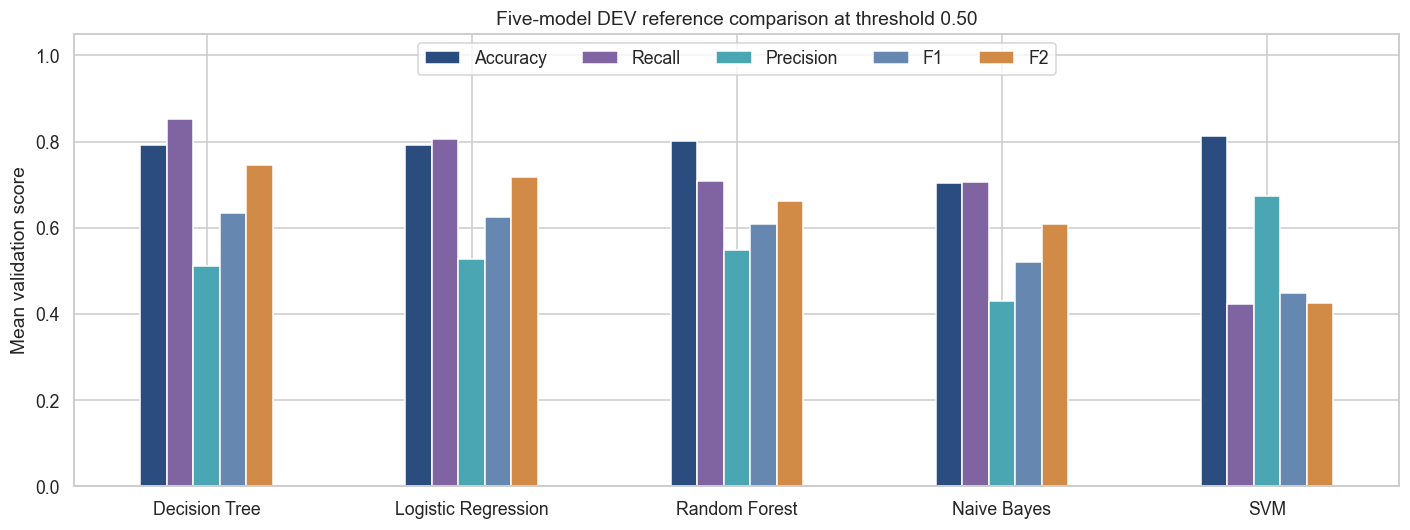

In [11]:
plot_data = model_comparison.set_index("model")[
    ["mean_accuracy", "mean_recall", "mean_precision", "mean_f1", "mean_f2"]]
fig, ax = plt.subplots(figsize=(13, 5))
plot_data.plot.bar(ax=ax, color=["#2B4C7E", "#8064A2", "#49A6B2", "#6687B0", "#D18B47"])
ax.set_title("Five-model DEV reference comparison at threshold 0.50")
ax.set_ylabel("Mean validation score")
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Accuracy", "Recall", "Precision", "F1", "F2"], loc="upper center", ncol=5)
plt.tight_layout()
comparison_figure = fig
plt.show()
plt.close(fig)


## 5. DEV algorithm and threshold selection using F2

For each of the five algorithms, search 0.00, 0.05, …, 1.00 using its saved
learner-grouped DEV out-of-fold predictions. Select each algorithm's highest-F2
threshold, then compare the resulting five model–threshold pairs.

F2 is F-beta with beta=2: it emphasizes recall while still accounting for
precision. This is a declared preference, not a promised recall percentage.
Within an algorithm, exact F2 ties prefer higher precision, then the higher
threshold. Apply the same tie-breaks between algorithms; remaining exact ties
use algorithm name for a reproducible order. Average Precision is not a selector.

The final table uses pooled out-of-fold metrics across all DEV records;
Section 4 reports mean fold metrics at 0.50. They have different aggregation.
Show false alerts, missed failures and alert counts alongside precision and recall.

Apply the same threshold search to the grade-only logistic reference. This is a
algorithm-selection stage, not the final fit. Section 6 keeps the selected algorithm
fixed, tunes Random Forest's parameters and reselects its threshold before TEST.
Do not change the rule because of TEST results. This is an exploratory follow-up:
TEST has already been inspected, and reusing DEV folds for model/threshold
selection makes the selected DEV score potentially optimistic.


In [12]:
def choose_threshold(y_true, scores, minimum_threshold=0.0):
    rows = [
        {"threshold": float(threshold), **metric_row(y_true, scores, threshold)}
        for threshold in np.round(np.linspace(0.00, 1.00, 21), 2)
    ]
    table = pd.DataFrame(rows)
    table["eligible_for_selection"] = table.threshold >= minimum_threshold
    ranked = table[table.eligible_for_selection].sort_values(
        ["f2", "precision", "threshold"], ascending=[False, False, False],
        kind="stable", na_position="last",
    )
    return float(ranked.iloc[0].threshold), table

def compare_model_thresholds(predictions_by_algorithm, minimum_threshold=0.0):
    rows, searches = [], {}
    for algorithm, oof in predictions_by_algorithm.items():
        threshold, searches[algorithm] = choose_threshold(oof[TARGET], oof.risk_score, minimum_threshold)
        rows.append({
            "algorithm": algorithm, "model": MODEL_LABELS[algorithm], "threshold": threshold,
            **metric_row(oof[TARGET], oof.risk_score, threshold),
        })
    ranking = pd.DataFrame(rows).sort_values(
        ["f2", "precision", "threshold", "algorithm"],
        ascending=[False, False, False, True], kind="stable", na_position="last",
    ).reset_index(drop=True)
    return ranking, searches

model_threshold_comparison, threshold_searches = compare_model_thresholds(oof_by_algorithm)
selected_algorithm = model_threshold_comparison.iloc[0]["algorithm"]
selected_threshold = float(model_threshold_comparison.iloc[0]["threshold"])
selected_oof = oof_by_algorithm[selected_algorithm].copy()
threshold_table = threshold_searches[selected_algorithm]
threshold_metrics = metric_row(selected_oof[TARGET], selected_oof.risk_score, selected_threshold)
grade_threshold, _ = choose_threshold(grade_oof[TARGET], grade_oof.risk_score)

print("Initial algorithm selection: reference configurations at their F2-selected thresholds.")
display_metrics(model_threshold_comparison)
print("Selected model's DEV threshold search:")
display_metrics(threshold_table[["threshold", "f2", "recall", "precision", "f1", "alerts", "fp", "fn"]])

# To display entire output
# columns = [
#     "threshold", "f2", "recall", "precision",
#     "f1", "alerts", "fp", "fn",
# ]

# with pd.option_context("display.max_rows", None, "display.max_columns", None):
#     for algorithm, search_table in threshold_searches.items():
#         print(
#             f"\n{MODEL_LABELS[algorithm]} — "
#             f"all {len(search_table)} tested thresholds"
#         )
#         display_metrics(search_table[columns])
        
display_metrics(pd.DataFrame([
    {"decision": "Selected model at common 0.50 threshold",
     **metric_row(selected_oof[TARGET], selected_oof.risk_score, 0.50)},
    {"decision": f"Selected model at DEV F2-selected threshold {selected_threshold:.2f}",
     **threshold_metrics},
]))
print(f"DEV-selected algorithm before hyperparameter tuning: {MODEL_LABELS[selected_algorithm]}; threshold: {selected_threshold:.2f}; "
      f"F2: {threshold_metrics['f2']:.3f}")
print(f"DEV recall: {threshold_metrics['recall']:.1%}; precision: {threshold_metrics['precision']:.1%}")
print(f"DEV alerts: {threshold_metrics['alerts']} of {threshold_metrics['rows']}; "
      f"false alerts: {threshold_metrics['fp']}; missed failures: {threshold_metrics['fn']}")


Initial algorithm selection: reference configurations at their F2-selected thresholds.


,algorithm,model,threshold,recall,precision,f1,f2,accuracy,tn,fp,fn,tp,alerts,rows,failures
0,random_forest,Random Forest,0.35,0.927,0.487,0.639,0.785,0.784,118,40,3,38,78,199,41
1,decision_tree,Decision Tree,0.55,0.854,0.5,0.631,0.748,0.794,123,35,6,35,70,199,41
2,svm,SVM,0.15,0.927,0.418,0.576,0.745,0.719,105,53,3,38,91,199,41
3,logistic,Logistic Regression,0.35,0.902,0.435,0.587,0.743,0.739,110,48,4,37,85,199,41
4,gaussian_nb,Naive Bayes,0.2,0.805,0.367,0.504,0.65,0.673,101,57,8,33,90,199,41


Selected model's DEV threshold search:


,threshold,f2,recall,precision,f1,alerts,fp,fn
0,0.0,0.565,1.0,0.206,0.342,199,158,0
1,0.05,0.643,1.0,0.265,0.418,155,114,0
2,0.1,0.671,0.976,0.299,0.457,134,94,1
3,0.15,0.707,0.976,0.336,0.5,119,79,1
4,0.2,0.725,0.951,0.371,0.534,105,66,2
5,0.25,0.75,0.951,0.406,0.569,96,57,2
6,0.3,0.768,0.951,0.433,0.595,90,51,2
7,0.35,0.785,0.927,0.487,0.639,78,40,3
8,0.4,0.751,0.854,0.507,0.636,69,34,6
9,0.45,0.721,0.805,0.508,0.623,65,32,8


,decision,recall,precision,f1,f2,accuracy,tn,fp,fn,tp,alerts,rows,failures
0,Selected model at common 0.50 threshold,0.707,0.518,0.598,0.659,0.804,131,27,12,29,56,199,41
1,Selected model at DEV F2-selected threshold 0.35,0.927,0.487,0.639,0.785,0.784,118,40,3,38,78,199,41


DEV-selected algorithm before hyperparameter tuning: Random Forest; threshold: 0.35; F2: 0.785
DEV recall: 92.7%; precision: 48.7%
DEV alerts: 78 of 199; false alerts: 40; missed failures: 3


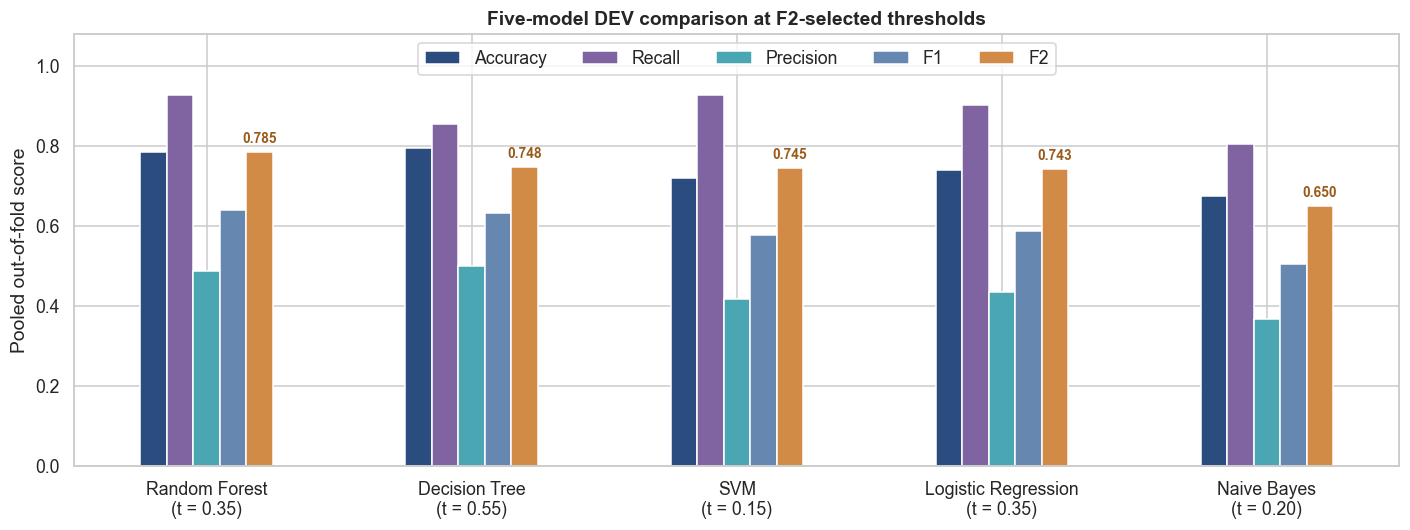

In [13]:
threshold_plot_data = model_threshold_comparison.assign(
    label=lambda d: d.apply(lambda r: f"{r['model']}\n(t = {r['threshold']:.2f})", axis=1)
).set_index("label")[["accuracy", "recall", "precision", "f1", "f2"]]

fig, ax = plt.subplots(figsize=(13, 5))
threshold_plot_data.plot.bar(
    ax=ax,
    color=["#2B4C7E", "#8064A2", "#49A6B2", "#6687B0", "#D18B47"],
)
# Annotate F2 bars (the 5th bar group) to highlight the selection metric
for bar in ax.containers[4]:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2, h + 0.015, f"{h:.3f}",
        ha="center", va="bottom", fontsize=9, fontweight="bold", color="#9A5B1A",
    )
ax.set_title("Five-model DEV comparison at F2-selected thresholds", fontweight="bold")
ax.set_ylabel("Pooled out-of-fold score")
ax.set_ylim(0, 1.08)
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Accuracy", "Recall", "Precision", "F1", "F2"], loc="upper center", ncol=5)
plt.tight_layout()
threshold_comparison_figure = fig
plt.show()
plt.close(fig)

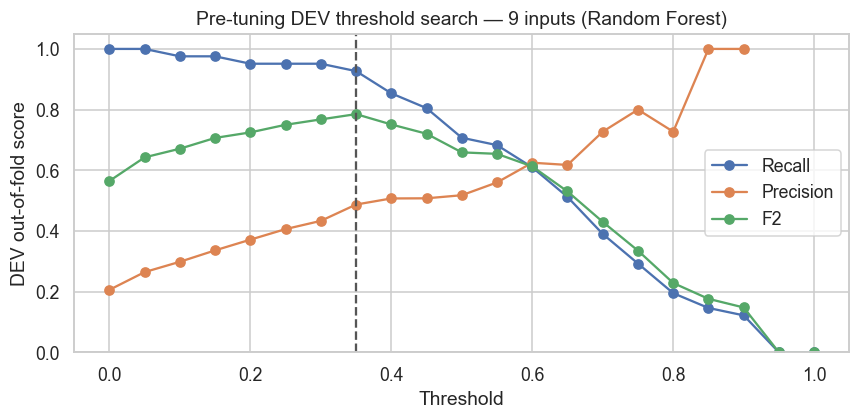

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(threshold_table.threshold, threshold_table.recall, marker="o", label="Recall")
ax.plot(threshold_table.threshold, threshold_table.precision, marker="o", label="Precision")
ax.plot(threshold_table.threshold, threshold_table.f2, marker="o", label="F2")
# Standalone dashed marker; the legend contains only the three metric curves.
ax.axvline(selected_threshold, color="#555555", linestyle="--", linewidth=1.5)
ax.set(xlabel="Threshold", ylabel="DEV out-of-fold score", ylim=(0, 1.05),
       title=f"Pre-tuning DEV threshold search — 9 inputs ({MODEL_LABELS[selected_algorithm]})")
ax.legend()
plt.tight_layout()
pre_tuning_threshold_figure = fig
plt.show()
plt.close(fig)


## 6. Tune the selected Model

The previous section selected Random Forest from the five reference algorithms.
Keep that algorithm choice fixed. Do not run a new hyperparameter competition
between all five algorithms.

Search Random Forest max_depth values **4, 3 and 6** on the same nine inputs and
saved learner-grouped DEV folds. Keep 300 trees, min_samples_leaf=5, balanced class
weights and the random seed fixed. The original depth 4 is included; reuse its
already-computed reference predictions. This is a small three-candidate search,
not an exhaustive search for every possible Random Forest setting.

Each candidate fits preprocessing inside its training folds, collects held-out
DEV scores and receives the same 21-threshold F2 search. Keep 0.35 as the minimum
eligible alert threshold, reflecting the stated reluctance to flag below
0.35–0.40. Scores below that limit remain visible but cannot be selected.
This is an operational constraint, not a guaranteed recall or a validated
probability boundary. Apply the same lower bound to the grade-only reference.
An earlier unrestricted/all-algorithm diagnostic favored 0.30 and is archived,
not hidden or adopted as the operating point.

Select the highest-F2 Random Forest parameter–threshold pair. Exact ties prefer
higher precision, then a higher threshold, then the first declared parameter
candidate. Report Random Forest before/after tuning under the same lower bound.

Algorithm, hyperparameter and threshold selection reuse DEV folds, so the chosen
DEV score can be optimistic. This is not nested cross-validation or a fresh
independent performance estimate. TEST has already been inspected and remains
exploratory. The next section refits the selected Random Forest on all DEV,
then evaluates its locked-in threshold. Other algorithms remain reference results;
they are not hyperparameter-tuned in this workflow.


Random Forest only: three parameter candidates at their eligible DEV F2-selected thresholds.


,model,candidate_id,parameters,threshold,f2,recall,precision,alerts,fp,fn
0,Random Forest,0,"{""max_depth"": 4}",0.35,0.785,0.927,0.487,78,40,3
1,Random Forest,1,"{""max_depth"": 3}",0.4,0.771,0.902,0.487,76,39,4
2,Random Forest,2,"{""max_depth"": 6}",0.35,0.771,0.902,0.487,76,39,4


Final selected Random Forest configuration:


,model,algorithm,parameters,threshold,recall,precision,f1,f2,accuracy,tn,fp,fn,tp,alerts,rows,failures
0,Random Forest,random_forest,"{""max_depth"": 4}",0.35,0.927,0.487,0.639,0.785,0.784,118,40,3,38,78,199,41


Random Forest before/after tuning: same DEV folds and minimum threshold.


,stage,threshold,recall,precision,f1,f2,accuracy,tn,fp,fn,tp,alerts,rows,failures
0,Before RF tuning,0.35,0.927,0.487,0.639,0.785,0.784,118,40,3,38,78,199,41
1,After RF tuning,0.35,0.927,0.487,0.639,0.785,0.784,118,40,3,38,78,199,41


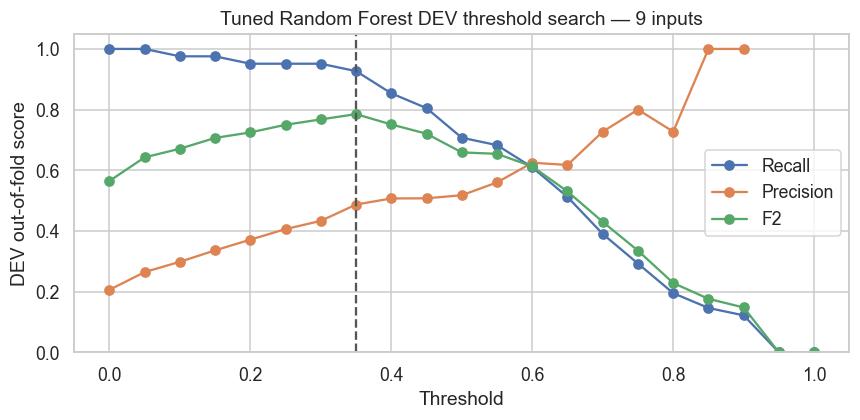

Final choice: Random Forest, parameters {'max_depth': 4}, threshold 0.35, F2 0.785
DEV catches 38 of 41 failing transitions, with 40 false alerts.
Algorithm kept fixed after Section 5; lock in RF parameters and threshold before TEST.


In [15]:
from sklearn.model_selection import ParameterGrid
import json

MIN_ALERT_THRESHOLD = 0.35  # Operational lower bound, not a recall target.
RF_PARAMETER_GRID = {"max_depth": [4, 3, 6]}  # Original setting first.

def tune_selected_model(frame, features, algorithm, parameter_grid,
                        reference_folds=None, reference_oof=None, minimum_threshold=0.0):
    assert frame.partition.eq("DEV").all(), "Tuning must use DEV records."
    default_parameters = build_pipeline(algorithm).named_steps["classifier"].get_params()
    results, searches, predictions = [], [], {}
    for candidate_id, parameters in enumerate(ParameterGrid(parameter_grid)):
        if (reference_folds is not None and reference_oof is not None
                and all(default_parameters[name] == value for name, value in parameters.items())):
            folds, oof = reference_folds, reference_oof
        else:
            folds, oof = run_grouped_cv(frame, features, algorithm, parameters=parameters)
        threshold, search = choose_threshold(oof[TARGET], oof.risk_score, minimum_threshold)
        parameter_text = json.dumps(parameters, sort_keys=True)
        results.append({
            "algorithm": algorithm, "model": MODEL_LABELS[algorithm],
            "candidate_id": candidate_id, "parameters": parameter_text, "threshold": threshold,
            "mean_fold_f2_at_050": float(folds.f2.mean()),
            **metric_row(oof[TARGET], oof.risk_score, threshold),
        })
        predictions[candidate_id] = (parameters, folds, oof)
        searches.append(search.assign(algorithm=algorithm, model=MODEL_LABELS[algorithm],
                                     candidate_id=candidate_id, parameters=parameter_text))
    ranking = pd.DataFrame(results).sort_values(
        ["f2", "precision", "threshold", "candidate_id"],
        ascending=[False, False, False, True], kind="stable", na_position="last")
    parameters, folds, oof = predictions[int(ranking.iloc[0].candidate_id)]
    return pd.DataFrame(results), parameters, folds, oof, pd.concat(searches, ignore_index=True)

# This research plan tunes only the algorithm already selected in Section 5.
# If new data select a different algorithm, stop and review the plan; do not force RF to win.
assert selected_algorithm == "random_forest", (
    "The initial comparison did not select Random Forest. Review the RF-only tuning plan.")
pre_tuning_model_threshold_comparison = model_threshold_comparison.copy()
before_threshold, _ = choose_threshold(
    selected_oof[TARGET], selected_oof.risk_score, MIN_ALERT_THRESHOLD)
before_tuning_metrics = metric_row(selected_oof[TARGET], selected_oof.risk_score, before_threshold)

hyperparameter_results, selected_parameters, tuned_folds, selected_oof, candidate_threshold_searches = tune_selected_model(
    dev_df, FEATURES, selected_algorithm, RF_PARAMETER_GRID,
    fold_results[selected_algorithm], oof_by_algorithm[selected_algorithm],
    minimum_threshold=MIN_ALERT_THRESHOLD)
selected_threshold, threshold_table = choose_threshold(
    selected_oof[TARGET], selected_oof.risk_score, MIN_ALERT_THRESHOLD)
threshold_metrics = metric_row(selected_oof[TARGET], selected_oof.risk_score, selected_threshold)
grade_threshold, _ = choose_threshold(grade_oof[TARGET], grade_oof.risk_score, MIN_ALERT_THRESHOLD)

print("Random Forest only: three parameter candidates at their eligible DEV F2-selected thresholds.")
display_metrics(hyperparameter_results[[
    "model", "candidate_id", "parameters", "threshold", "f2", "recall", "precision",
    "alerts", "fp", "fn"]])
tuned_model_summary = pd.DataFrame([{
    "model": MODEL_LABELS[selected_algorithm], "algorithm": selected_algorithm,
    "parameters": json.dumps(selected_parameters, sort_keys=True),
    "threshold": selected_threshold, **threshold_metrics,
}])
print("Final selected Random Forest configuration:")
display_metrics(tuned_model_summary)
print("Random Forest before/after tuning: same DEV folds and minimum threshold.")
display_metrics(pd.DataFrame([
    {"stage": "Before RF tuning", "threshold": before_threshold, **before_tuning_metrics},
    {"stage": "After RF tuning", "threshold": selected_threshold, **threshold_metrics},
]))

# Uncomment to show every threshold for all three RF candidates.
# with pd.option_context("display.max_rows", None, "display.max_columns", None):
#     for candidate_id, search in candidate_threshold_searches.groupby("candidate_id", sort=False):
#         print("Random Forest candidate", candidate_id, search.parameters.iloc[0])
#         display_metrics(search[["threshold", "eligible_for_selection", "f2", "recall",
#                                "precision", "f1", "alerts", "fp", "fn"]])

fig, ax = plt.subplots(figsize=(8, 4))
for metric, label in [("recall", "Recall"), ("precision", "Precision"), ("f2", "F2")]:
    ax.plot(threshold_table.threshold, threshold_table[metric], marker="o", label=label)
ax.axvline(selected_threshold, color="#555555", linestyle="--", linewidth=1.5)
ax.set(xlabel="Threshold", ylabel="DEV out-of-fold score", ylim=(0, 1.05),
       title="Tuned Random Forest DEV threshold search — 9 inputs")
ax.legend()
plt.tight_layout()
threshold_figure = fig
plt.show()
plt.close(fig)

print(f"Final choice: {MODEL_LABELS[selected_algorithm]}, parameters {selected_parameters}, "
      f"threshold {selected_threshold:.2f}, F2 {threshold_metrics['f2']:.3f}")
print(f"DEV catches {threshold_metrics['tp']} of {threshold_metrics['failures']} failing transitions, "
      f"with {threshold_metrics['fp']} false alerts.")
print("Algorithm kept fixed after Section 5; lock in RF parameters and threshold before TEST.")


## 7. Lock in the tuned model and evaluate TEST

Lock in the Random Forest settings, nine inputs and alert threshold selected on DEV.
Fit the selected configuration on all DEV records, then evaluate TEST without changing
those choices to improve its results.

This run fits a new model on DEV, but uses the same previously inspected TEST learners
and records. It is **not a fresh, untouched test cohort**. The evaluation remains
exploratory. TEST records are not used to fit the model in this run.

The grade-only reference remains unweighted Logistic Regression with C=1 and a
DEV-selected threshold. Low/Moderate/High are descriptive score bands; the binary alert
threshold is separate. Scores are not calibrated percentage chances.


In [16]:
model = fit_model(dev_df, FEATURES, selected_algorithm, parameters=selected_parameters)
grade_reference = fit_model(dev_df, ["previous_final_grade"], "logistic", balanced=False)
bundle = {
    "pipeline": model, "features": FEATURES, "algorithm": selected_algorithm,
    "threshold": selected_threshold, "parameters": selected_parameters,
    "metadata": {
        "model_version": "English nine-input DEV hyperparameter and F2 threshold follow-up",
        "evidence_scope": "Historical English quarter transitions",
        "algorithm_selection_rule": "Highest initial DEV OOF F2 after threshold searches for five reference algorithms; keep algorithm fixed and tune selected Random Forest only",
        "threshold_rule": "Highest eligible DEV OOF F2; evaluate grid 0.00–1.00, step 0.05; operational minimum 0.35; ties: precision, then higher threshold",
        "hyperparameter_tuning_scope": "Selected Random Forest only",
        "hyperparameter_candidate_count": 3,
        "minimum_alert_threshold": MIN_ALERT_THRESHOLD,
        "previously_inspected_test": True,
    },
}

def bundle_predict(bundle, frame):
    scores = predict_scores(bundle["pipeline"], frame, bundle["features"])
    return pd.DataFrame({
        "risk_score": scores, "risk_level": [risk_band(s) for s in scores],
        "predicted_at_risk": (scores >= bundle["threshold"]).astype(int),
    }, index=frame.index)

test_predictions = pd.concat([
    test_df[["transition_id", GROUP, "section_id", "previous_period", "prediction_period",
             "final_subject_grade", TARGET]],
    bundle_predict(bundle, test_df),
], axis=1)
overall_metrics = metric_row(test_df[TARGET], test_predictions.risk_score, selected_threshold)
reference_scores = {
    "Predict passing": (np.zeros(len(test_df)), 0.5),
    "Previous grade below 75": ((test_df.previous_final_grade < 75).astype(float), 0.5),
    "Grade-only logistic": (predict_scores(grade_reference, test_df, ["previous_final_grade"]), grade_threshold),
}
test_comparison = pd.DataFrame([
    {"model": MODEL_LABELS[selected_algorithm], "threshold": selected_threshold, **overall_metrics},
    *[{"model": name, "threshold": threshold, **metric_row(test_df[TARGET], scores, threshold)}
      for name, (scores, threshold) in reference_scores.items()],
])
# Keep all baselines in the saved results; show only the learned grade-only reference here.
display_metrics(test_comparison[test_comparison.model.isin(
    [MODEL_LABELS[selected_algorithm]]
)].reset_index(drop=True))


,model,threshold,recall,precision,f1,f2,accuracy,tn,fp,fn,tp,alerts,rows,failures
0,Random Forest,0.35,0.8,0.381,0.516,0.656,0.7,27,13,2,8,21,50,10


,section,recall,precision,f1,f2,accuracy,tn,fp,fn,tp,alerts,rows,failures
0,G8-CAYETANO,0.778,0.438,0.56,0.673,0.633,12,9,2,7,16,30,9
1,G8-DEFENSOR,1.0,0.2,0.333,0.556,0.8,15,4,0,1,5,20,1


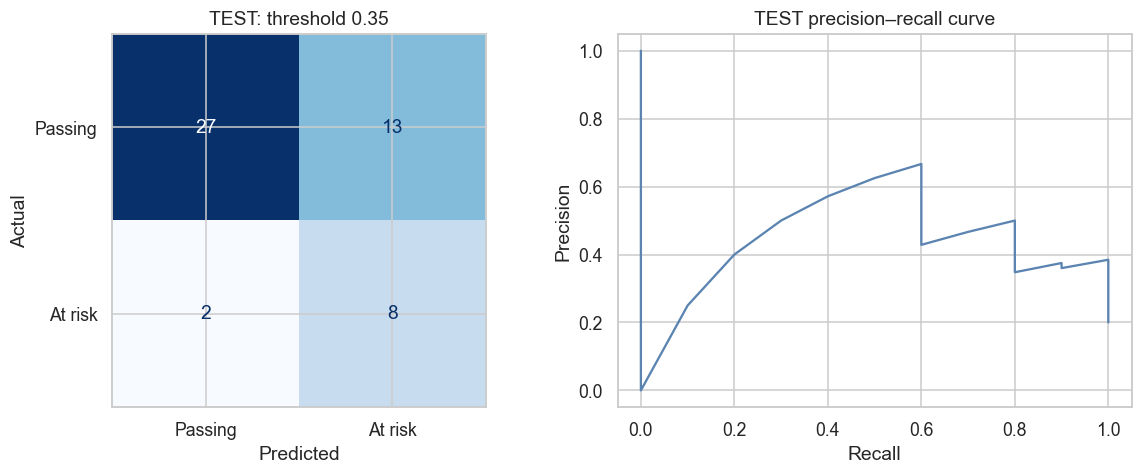

TEST catches 8 of 10 failing transitions (80% recall), with 13 false alerts.
Report the observed TEST result; do not adjust the threshold using TEST.
These are 50 transitions from 17 learners; repeated periods are not independent learners.


In [17]:
subgroup_results = pd.DataFrame([
    {"section": section, **metric_row(rows[TARGET], rows.risk_score, selected_threshold)}
    for section, rows in test_predictions.groupby("section_id")
])
display_metrics(subgroup_results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    test_predictions[TARGET], test_predictions.predicted_at_risk,
    display_labels=["Passing", "At risk"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"TEST: threshold {selected_threshold:.2f}")
axes[0].set(xlabel="Predicted", ylabel="Actual")
precision, recall, _ = precision_recall_curve(test_predictions[TARGET], test_predictions.risk_score)
axes[1].plot(recall, precision, color="#5B84B1")
axes[1].set(xlabel="Recall", ylabel="Precision", title="TEST precision–recall curve")
plt.tight_layout()
evaluation_figure = fig
plt.show()
plt.close(fig)

print(f"TEST catches {overall_metrics['tp']} of {overall_metrics['failures']} failing transitions "
      f"({overall_metrics['recall']:.0%} recall), with {overall_metrics['fp']} false alerts.")
print("Report the observed TEST result; do not adjust the threshold using TEST.")
print(f"These are {len(test_df)} transitions from {test_df[GROUP].nunique()} learners; "
      "repeated periods are not independent learners.")


### Brief TEST interpretation

This summary uses the current evaluation results; it does not tune the model.


In [18]:
# Brief interpretation of current TEST results; no training or selection here.
reference = test_comparison[test_comparison.model == "Grade-only logistic"].iloc[0]
metric_labels = {"recall": "recall", "precision": "precision", "f1": "F1", "f2": "F2", "accuracy": "accuracy"}
rf_higher = [label for name, label in metric_labels.items() if overall_metrics[name] > reference[name]]
grade_higher = [label for name, label in metric_labels.items() if reference[name] > overall_metrics[name]]

display(Markdown(
    f"- **TEST result:** {MODEL_LABELS[selected_algorithm]} at threshold {selected_threshold:.2f}, "
    f"on {len(test_df)} period-transition records from {test_df[GROUP].nunique()} learners: "
    f"caught {overall_metrics['tp']} of {overall_metrics['failures']} failures, "
    f"missed {overall_metrics['fn']}, raised {overall_metrics['fp']} false alerts, and correctly "
    f"left {overall_metrics['tn']} passing records unflagged. "
    f"Recall {overall_metrics['recall']:.0%}; precision {overall_metrics['precision']:.1%}; "
    f"F1 {overall_metrics['f1']:.3f}; F2 {overall_metrics['f2']:.3f}; accuracy {overall_metrics['accuracy']:.0%}.\n\n"
    f"- **Baseline comparison:** Grade-only logistic caught {int(reference.tp)} failures "
    f"with {int(reference.fp)} false alerts. Random Forest scores higher on "
    f"{', '.join(rf_higher) or 'none of these metrics'}; the baseline scores higher on "
    f"{', '.join(grade_higher) or 'none of these metrics'}. "
    "This does not establish overall superiority on new learners.\n\n"
    "- **Reliability:** TEST has already been inspected, contains few failures, and includes repeated "
    "periods per learner. DEV selection also reuses its folds. These are exploratory results, "
    "not fresh independent evidence.\n\n"
    "- **Scope:** English quarterly data only. Cayetano grades; Defensor grades "
    "are as recorded. Scores are not calibrated failure probabilities. Term deployment needs "
    "validation on completed term outcomes. Full methodological details remain in "
    "`outputs/current/evaluation_report.json`."
))


- **TEST result:** Random Forest at threshold 0.35, on 50 period-transition records from 17 learners: caught 8 of 10 failures, missed 2, raised 13 false alerts, and correctly left 27 passing records unflagged. Recall 80%; precision 38.1%; F1 0.516; F2 0.656; accuracy 70%.

- **Baseline comparison:** Grade-only logistic caught 6 failures with 4 false alerts. Random Forest scores higher on recall, F2; the baseline scores higher on precision, F1, accuracy. This does not establish overall superiority on new learners.

- **Reliability:** TEST has already been inspected, contains few failures, and includes repeated periods per learner. DEV selection also reuses its folds. These are exploratory results, not fresh independent evidence.

- **Scope:** English quarterly data only. Cayetano grades; Defensor grades are as recorded. Scores are not calibrated failure probabilities. Term deployment needs validation on completed term outcomes. Full methodological details remain in `outputs/current/evaluation_report.json`.

## 8. Save results for the Tkinter simulator

Save the current model and a snapshot of its TEST replay records in `outputs/current`.
`model.joblib` contains the fitted preprocessing pipeline and Random Forest, the ordered nine inputs,
the DEV-selected threshold and model settings. Saving it does not train another model.
`replay_records.csv` contains the existing TEST records for selecting historical examples in the GUI.
The GUI loads both files, applies the saved preprocessing and model to the nine inputs, then uses
the saved threshold for the alert and the score bands for Low/Moderate/High. It does not retrain.
Actual outcomes in replay records are for comparison only, never prediction inputs.
The reference, tuning and threshold tables plus three main figures support Chapter 4;
they are reports, not models the GUI needs to run. All baseline rows remain in the saved TEST table.
Running this section updates this one output folder; it does not create a new run tree, hash files
or require a manifest. The saved learner partition CSV is retained for subsequent runs.

Use the same Python/library environment for analysis and simulation. Load only the joblib
file generated by this notebook.


In [19]:
import json
import joblib
import sklearn
import platform

output_dir = pipeline_dir / "outputs" / "current"
output_dir.mkdir(parents=True, exist_ok=True)
if not split_path.is_file():
    df[["transition_id", "partition", "cv_fold"]].to_csv(split_path, index=False)

joblib.dump(bundle, output_dir / "model.joblib") # Export model
test_df.to_csv(output_dir / "replay_records.csv", index=False)
model_comparison.to_csv(output_dir / "model_comparison.csv", index=False)
threshold_table.to_csv(output_dir / "threshold_search.csv", index=False)
pre_tuning_model_threshold_comparison.to_csv(output_dir / "pre_tuning_model_threshold_comparison.csv", index=False)
hyperparameter_results.to_csv(output_dir / "hyperparameter_search.csv", index=False)
tuned_model_summary.to_csv(output_dir / "tuned_model_summary.csv", index=False)
candidate_threshold_searches.to_csv(output_dir / "hyperparameter_threshold_search.csv", index=False)
model_threshold_comparison.to_csv(output_dir / "model_threshold_comparison.csv", index=False)
pd.concat([
    search.assign(algorithm=algorithm, model=MODEL_LABELS[algorithm])
    for algorithm, search in threshold_searches.items()
], ignore_index=True).to_csv(output_dir / "all_model_threshold_search.csv", index=False)
test_comparison.to_csv(output_dir / "test_comparison.csv", index=False)
test_predictions.to_csv(output_dir / "test_predictions.csv", index=False)
class_imbalance_figure.savefig(output_dir / "class_imbalance.png", dpi=150, bbox_inches="tight")
target_skew_figure.savefig(output_dir / "target_grade_skewness.png", dpi=150, bbox_inches="tight")
comparison_figure.savefig(output_dir / "model_comparison.png", dpi=150)
threshold_comparison_figure.savefig(output_dir / "model_threshold_comparison.png", dpi=150, bbox_inches="tight")
evaluation_figure.savefig(output_dir / "final_evaluation.png", dpi=150)
threshold_figure.savefig(output_dir / "threshold_selection.png", dpi=150)
evaluation_report = {
    "algorithm": selected_algorithm, "features": FEATURES, "threshold": selected_threshold,
    "selected_parameters": selected_parameters, "hyperparameter_grid": RF_PARAMETER_GRID,
    "hyperparameter_tuning_scope": "Selected Random Forest only",
    "hyperparameter_candidate_count": len(hyperparameter_results),
    "minimum_alert_threshold": MIN_ALERT_THRESHOLD,
    "minimum_threshold_reason": "Operational lower bound reflecting the requested 0.35–0.40 comfort range, not a guaranteed recall or probability boundary",
    "hyperparameter_selection_rule": "Highest pooled DEV OOF F2 after threshold search; ties: precision, higher threshold, declared candidate order",
    "algorithm_selection_metric": "Initial five-reference-algorithm DEV F2 after threshold searches; algorithm then kept fixed",
    "algorithm_tie_break": "Higher precision, then higher threshold, then algorithm name",
    "average_precision_role": "Supporting ranking metric only; not used for selection",
    "threshold_selection_metric": "F2 among eligible thresholds", "threshold_grid": [0.00, 1.00, 0.05],
    "threshold_tie_break": "Higher precision, then higher threshold",
    "dev_metrics": threshold_metrics,
    "test_metrics": overall_metrics, "test_learners": int(test_df[GROUP].nunique()),
    "python_version": platform.python_version(), "scikit_learn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "study_design": "Exploratory follow-up on the same historical learner partitions",
    "limitations": [
        "TEST was inspected before this follow-up; this is not a fresh external test.",
        "DEV hyperparameter, model and threshold selection share folds and can be optimistic; no nested-CV performance estimate.",
        "Only three declared Random Forest depth settings were searched; other algorithms retain reference configurations.",
        "The 0.35 minimum alert threshold is an operational constraint, not a statistically validated boundary.",
        "SVM internal probability estimation is not learner-group-aware; outer DEV folds are learner-disjoint.",
        "Few learners and failing outcomes limit conclusions; transitions repeat learners.",
        "Cayetano grades; Defensor grades are as recorded.",
        "Task counts and coverage are excluded from the nine model inputs.",
        "English quarter records do not validate three-term performance.",
        "Risk scores are not calibrated probabilities and do not establish causal effects.",
    ],
}
(output_dir / "evaluation_report.json").write_text(
    json.dumps(evaluation_report, indent=2, allow_nan=False), encoding="utf-8")
print("Saved results and simulator assets:", output_dir)

Saved results and simulator assets: C:\Users\User\Desktop\Capstone\At-risk DataFrame\Model Pipeline\outputs\current


## Scope and next steps

Deploy only for English after validation on new learners. Phil-IRI here is the English baseline.
The task is **next-period subject failure risk from completed previous-period records**.
A Week-5 or mid-cycle model would require a separate dataset with dated predictor availability.

For term data, use the completed previous term's EXS PS for `qa_pct`.
Under the standard English template that PS is
`30*ST1/HPS1 + 30*ST2/HPS2 + 40*TE/HPSTE`; use the saved template's configuration.
The outer examination component weight used for the final grade is configurable.
MAPEH is outside this English model's scope. Compare quarterly and term feature distributions,
confirm attendance boundaries, and validate predictions after the target term ends.

The active model uses nine inputs, excluding task counts and coverage.
A comparison without explicit `qa_pct` remains a useful exploratory follow-up. Removing `qa_pct` does not remove exam information from
`previous_final_grade`. Neither these comparisons nor a higher recall on this historical cohort
establishes transfer to term data.
